# Look at the raw data: photos and their XML labels

Loads 10 random **Japan** training photos with their XML annotation files and shows each photo twice:

- **left:** the photo as it is;
- **right:** the same photo with every XML box highlighted.

Our 4 classes are coloured. Other codes (D43 crosswalk blur, D44 white-line blur, D50) are drawn **grey and dashed**, because we will treat them as "none".

In [1]:
import sys
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch, Rectangle
from PIL import Image

sys.path.insert(0, str(Path.cwd().parents[1]))  # backend/, so `ml` can be imported
from ml import config

IMAGES = config.RAW / "Japan" / "train" / "images"
XMLS = config.RAW / "Japan" / "train" / "annotations" / "xmls"
print(len(list(XMLS.glob("*.xml"))), "Japan XML files")

10506 Japan XML files


## 1. Read one XML file

Each XML lists the photo size and one `<object>` per damage, with its code (`<name>`) and box corners (`<bndbox>`).

In [2]:
def read_xml(path):
    root = ET.parse(path).getroot()
    boxes = []
    for obj in root.findall("object"):
        b = obj.find("bndbox")
        boxes.append({
            "code": obj.find("name").text,
            "xmin": int(float(b.find("xmin").text)),
            "ymin": int(float(b.find("ymin").text)),
            "xmax": int(float(b.find("xmax").text)),
            "ymax": int(float(b.find("ymax").text)),
        })
    return root.find("filename").text, boxes


example = sorted(XMLS.glob("*.xml"))[0]
print(example.name)
print(example.read_text()[:600])

Japan_000000.xml
<annotation>
	<folder>images</folder>
	<filename>Japan_000000.jpg</filename>
	<size>
		<width>600</width>
		<height>600</height>
		<depth>3</depth>
	</size>
	<segmented>0</segmented>
	<object>
		<name>D20</name>
		<pose>Unspecified</pose>
		<truncated>1</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>406</xmin>
			<ymin>475</ymin>
			<xmax>600</xmax>
			<ymax>596</ymax>
		</bndbox>
	</object>
	<object>
		<name>D40</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>409</xmin>
			<ymin>373</ymin>
			<xmax>598</xmax>
			<ymax>472


## 2. Pick 10 photos

Random, with the fixed seed, from photos that have at least one box.

In [3]:
rng = np.random.default_rng(config.SEED)
with_boxes = [p for p in sorted(XMLS.glob("*.xml")) if read_xml(p)[1]]
picked = rng.choice(with_boxes, size=10, replace=False)

rows = []
for p in picked:
    filename, boxes = read_xml(p)
    for b in boxes:
        rows.append({"image": filename, **b})
table = pd.DataFrame(rows)
print(len(with_boxes), "of", len(list(XMLS.glob('*.xml'))), "photos have at least one box")
table

9712 of 10506 photos have at least one box


,image,code,xmin,ymin,xmax,ymax
0,Japan_001138.jpg,D20,226,403,347,597
1,Japan_010104.jpg,D44,362,500,451,593
2,Japan_010104.jpg,D44,60,505,183,585
3,Japan_010104.jpg,D00,363,501,448,596
4,Japan_001183.jpg,D00,334,418,382,529
5,Japan_001183.jpg,D20,157,552,519,600
6,Japan_001183.jpg,D20,518,486,600,560
7,Japan_008550.jpg,D50,177,451,236,470
8,Japan_008550.jpg,D10,278,547,434,575
9,Japan_005743.jpg,D44,366,434,481,560


In [4]:
table["code"].value_counts()

code
D20    4
D44    4
D00    4
D50    2
D10    2
D40    2
D43    1
Name: count, dtype: int64

## 3. Photo vs photo + XML boxes

<Figure size 1200x60 with 0 Axes>

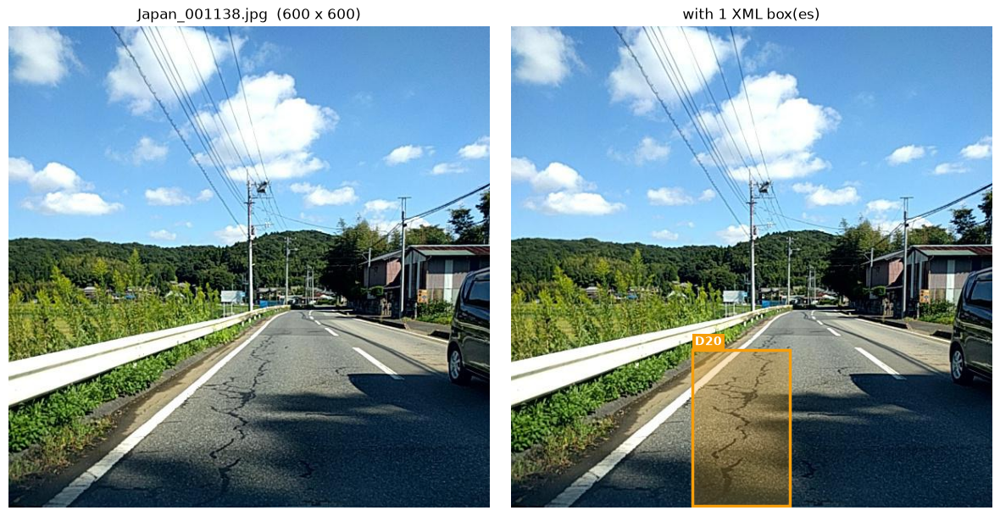

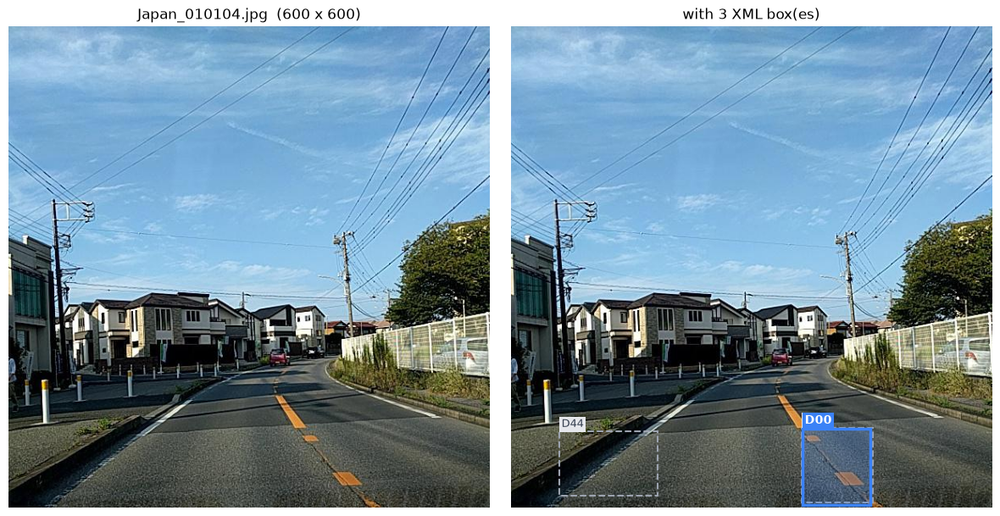

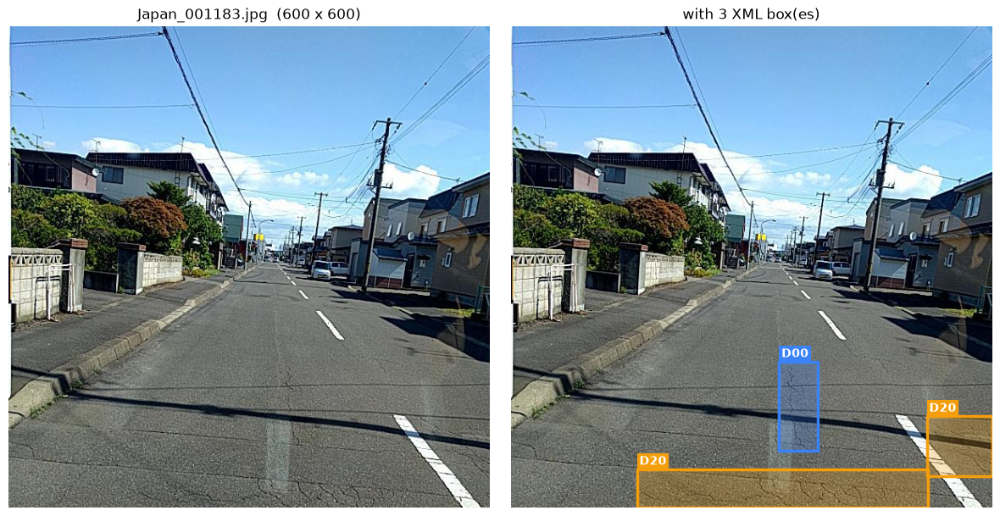

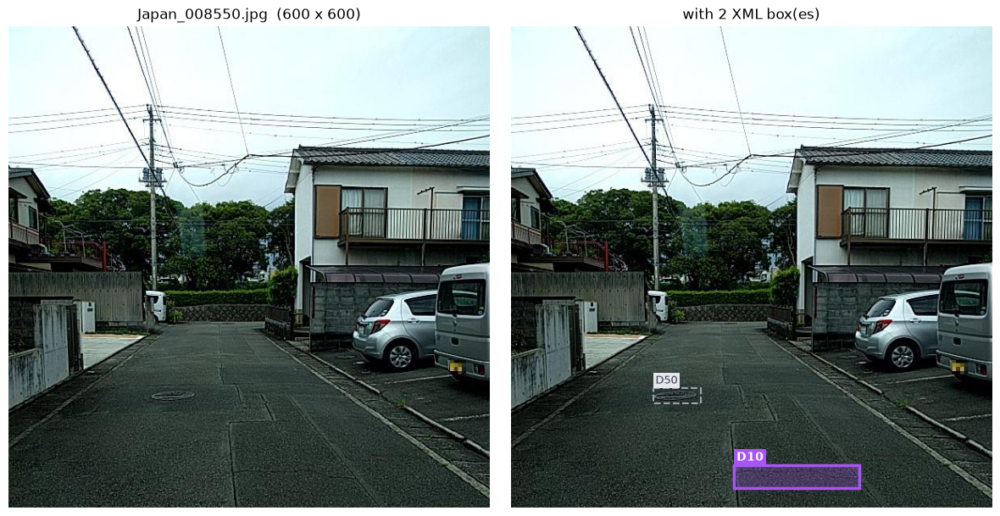

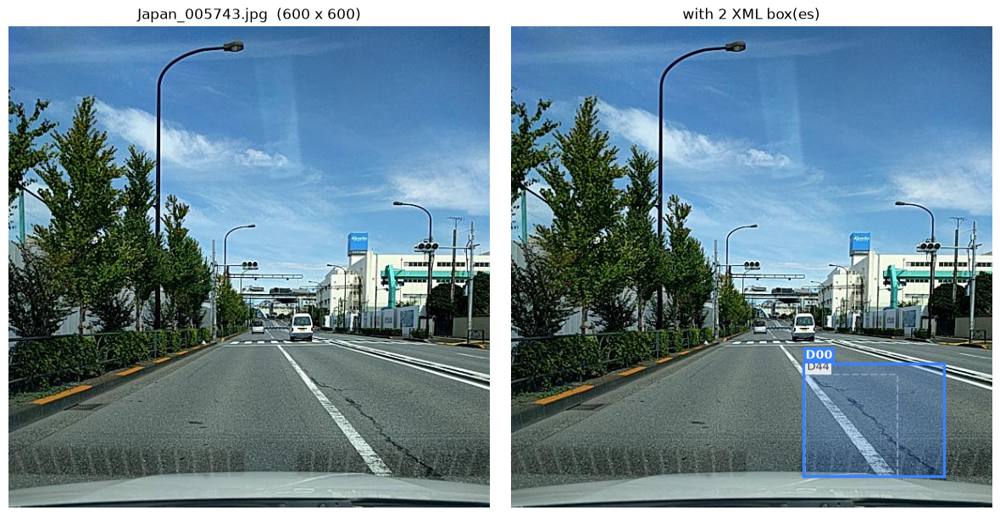

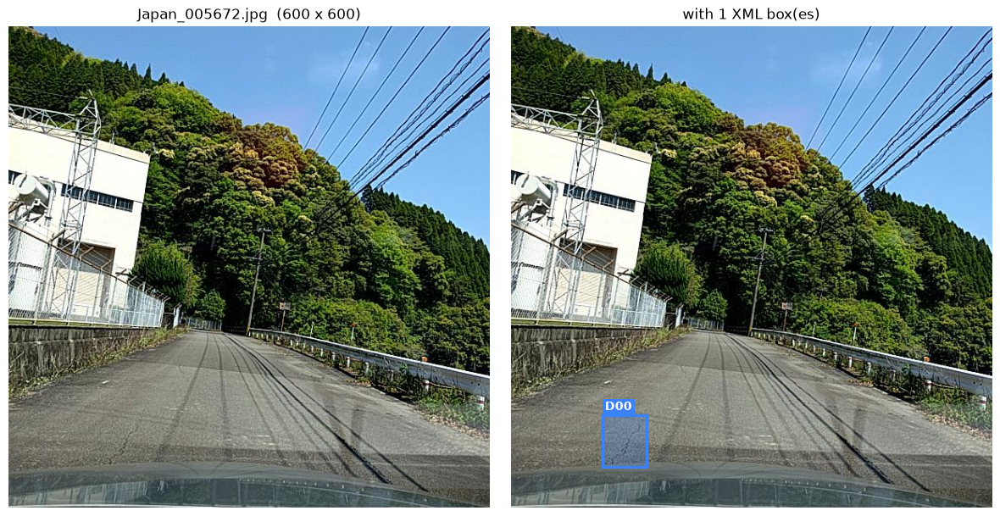

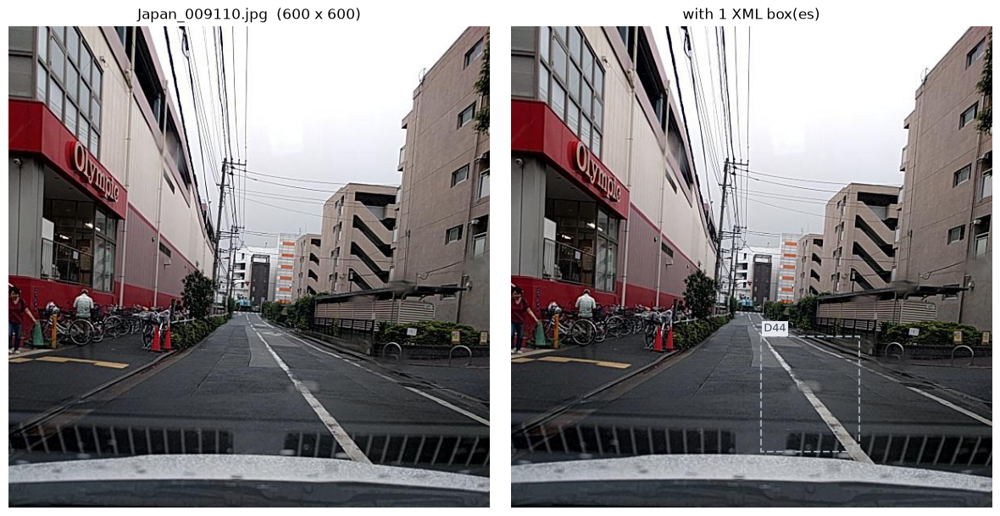

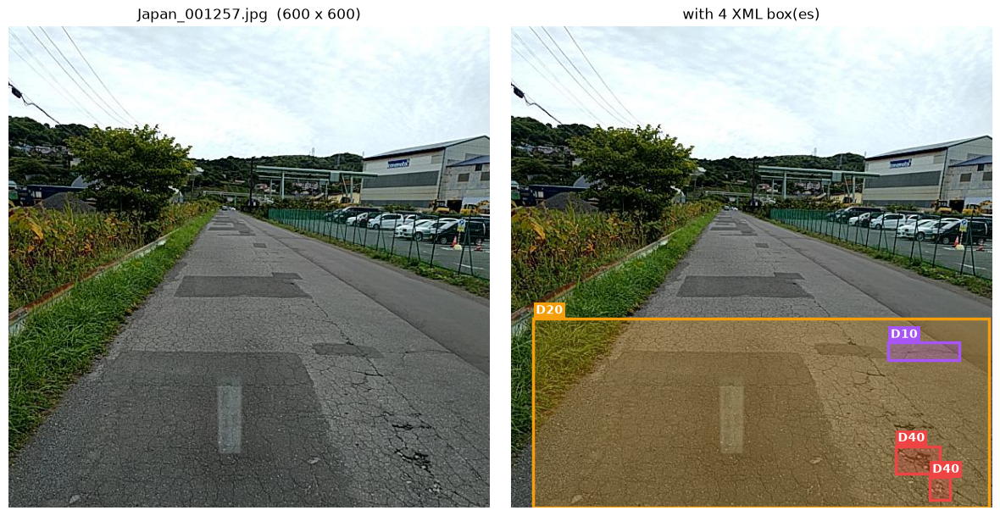

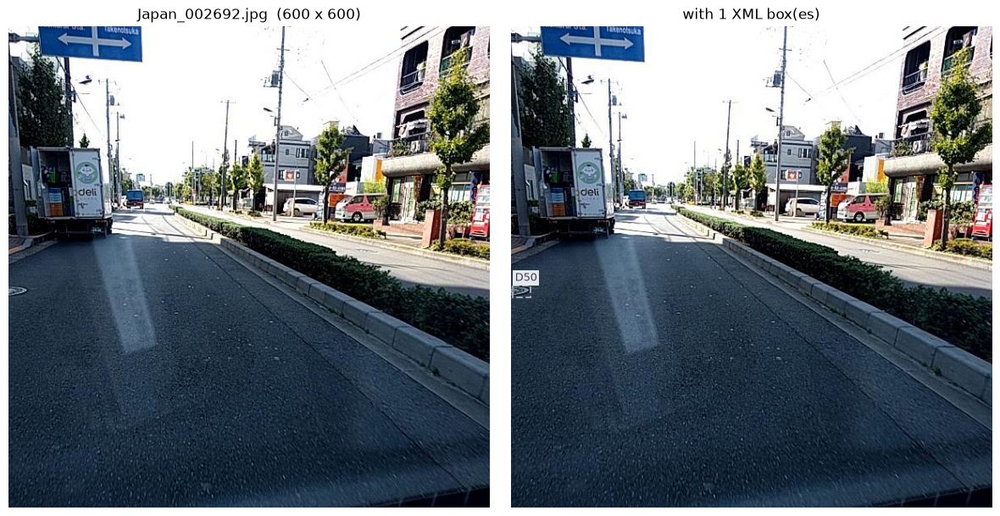

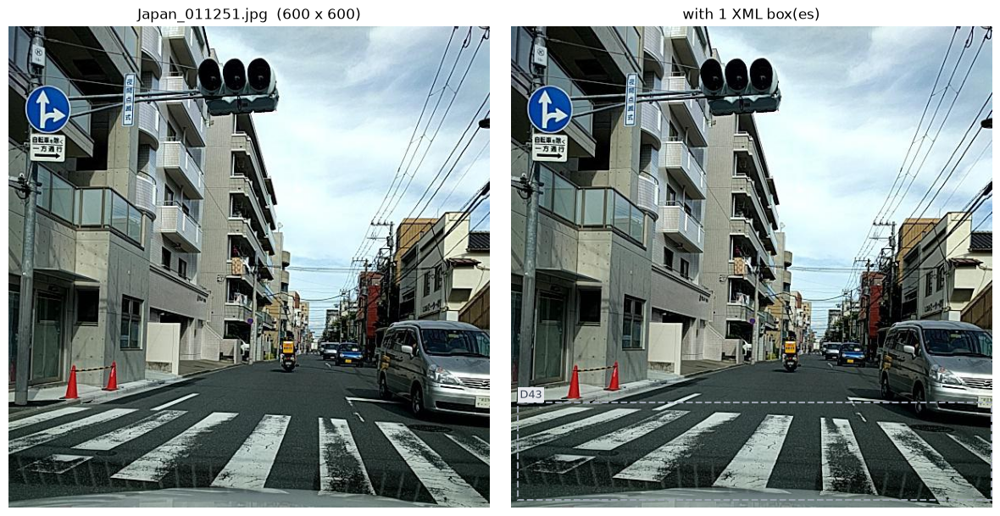

In [5]:
COLORS = {"D00": "#3b82f6", "D10": "#a855f7", "D20": "#f59e0b", "D40": "#ef4444"}
NAMES = {"D00": "Longitudinal crack", "D10": "Transverse crack", "D20": "Alligator crack", "D40": "Pothole"}


def show(xml_path):
    filename, boxes = read_xml(xml_path)
    img = Image.open(IMAGES / filename).convert("RGB")
    fig, (left, right) = plt.subplots(1, 2, figsize=(12, 6))
    left.imshow(img)
    left.set_title(f"{filename}  ({img.width} x {img.height})")
    right.imshow(img)
    right.set_title(f"with {len(boxes)} XML box(es)")
    for b in boxes:
        w, h = b["xmax"] - b["xmin"], b["ymax"] - b["ymin"]
        if b["code"] in COLORS:
            c = COLORS[b["code"]]
            right.add_patch(Rectangle((b["xmin"], b["ymin"]), w, h, facecolor=c, alpha=0.25))
            right.add_patch(Rectangle((b["xmin"], b["ymin"]), w, h, fill=False, edgecolor=c, linewidth=2.5))
            right.text(b["xmin"] + 3, b["ymin"] - 6, b["code"], color="white", fontsize=10, weight="bold",
                       bbox={"facecolor": c, "edgecolor": "none", "pad": 2})
        else:
            right.add_patch(Rectangle((b["xmin"], b["ymin"]), w, h, fill=False, edgecolor="#9ca3af", linewidth=1.5, linestyle="--"))
            right.text(b["xmin"] + 3, b["ymin"] - 6, b["code"], color="#374151", fontsize=9,
                       bbox={"facecolor": "#e5e7eb", "edgecolor": "none", "pad": 2})
    for ax in (left, right):
        ax.axis("off")
    plt.tight_layout()
    plt.show()


legend = [Patch(color=c, label=f"{k} · {NAMES[k]}") for k, c in COLORS.items()]
legend.append(Patch(facecolor="white", edgecolor="#9ca3af", linestyle="--", label="other code → 'none'"))
fig = plt.figure(figsize=(12, 0.6))
fig.legend(handles=legend, loc="center", ncol=5, frameon=False)
plt.show()

for p in picked:
    show(p)